# Лабораторная 3. Кластеризация методом DBSCAN
Выполнил: Двиков Даниил Владиславович

Активируем библиотеки

In [52]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import KMeans

import os

Задаем рабочую папку

In [53]:
os.chdir("E:/анализ данных/1 lab")


In [54]:
df = pd.read_csv("Леденцы.dat", sep=";")

In [55]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [56]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Во всех столбцах по 338 значений, значит, пропусков нет. Оценки везде лежат от 2 до 5, медиана у всех высказываний 3, то есть типичный ответ нейтральный.

Средние оценки близки, от 3,2 до 3,6. Чаще соглашаются с лечебными высказываниями (V9–V11) и про свежесть (V1–V3): у них 75-й процентиль равен 5, то есть как минимум четверть людей полностью согласны. Сладкое и концентрацию (V5–V8) поддерживают реже: 75-й процентиль у них 3, значит, согласных меньше четверти.

Стандартные отклонения у всех переменных похожие (0,82–0,99)

In [57]:
print(df.dtypes)
print('Все значения в данных:', np.unique(df.values))

V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object
Все значения в данных: [2 3 4 5]


Видим, что используется порядковая шкала от 2 до 5. Все 11 переменных измерены в одной и той же шкале с одинаковым диапазоном, поэтому стандартизация данных не нужна.

## Подберём параметры eps и MinSamples
Возьмем min_samples = 12, по правилу кол-во признаков (11) + 1. Построим график до 12-го ближайщего объекта.

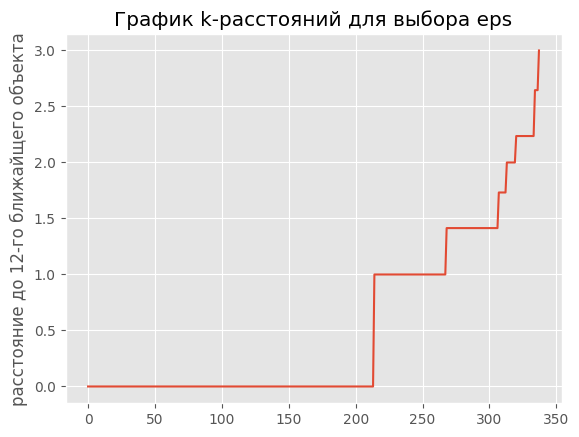

In [58]:
from sklearn.neighbors import NearestNeighbors
min_samples = 12
nn = NearestNeighbors(n_neighbors=min_samples).fit(df)
dist, _ = nn.kneighbors(df)
k_dist = np.sort(dist[:, -1]) 
plt.title('График k-расстояний для выбора eps')
plt.plot(k_dist)
plt.ylabel('расстояние до 12-го ближайщего объекта')
plt.show()


In [59]:
patterns = df.iloc[:, :11].value_counts()
print('В наборах с частотой >= 12:', patterns[patterns >= 12].sum(), '| k-расстояние = 0:', (k_dist == 0).sum())

В наборах с частотой >= 12: 214 | k-расстояние = 0: 214


Из-за дискретного характера исходных признаков и наличия множественных повторяющихся профилей график расстояний до 12-го соседа имеет ступенчатую форму и не содержит выраженного излома. Нулевое k-расстояние у 213 респондентов, чьи ответы повторяются 12 и более раз, поэтому скачок с 0 до 1 вызван дубликатами

###  Silhouette для автоматического определения значений параметров

In [60]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

X = df.iloc[:, :11]
n = len(X)

eps_grid = [np.sqrt(m) + 1e-6 for m in range(1, 13)]
min_samples_grid = [5, 8, 10, 12, 15, 20, 25, 30]

max_noise = 0.10  # в шуме не больше 10 % выборки
min_size = 0.05 # каждый кластер — не меньше 5 % выборки

results = []
best = None

# Поиск на решётке (grid search)
for m, eps in enumerate(eps_grid, start=1):
    for ms in min_samples_grid:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        noise = labels == -1
        sizes = np.bincount(labels[~noise]) if (~noise).any() else np.array([], dtype=int)
        n_clusters = len(sizes)

        if n_clusters > 1 and (~noise).sum() > n_clusters:
            sil = silhouette_score(X[~noise], labels[~noise])
        else:
            sil = np.nan

        ok = n_clusters > 1 and noise.mean() <= max_noise and sizes.min() >= min_size * n

        results.append({'eps': eps, 'eps (sqrt m)': f'sqrt {m} = {np.sqrt(m):.2f}', 'min_samples': ms,
                        'кластеров': n_clusters, 'шум': noise.sum(),
                        'мин. кластер': sizes.min() if n_clusters else 0,
                        'силуэт': sil, 'допустим': ok})

        if ok and (best is None or sil > best['силуэт']):
            best = results[-1]

res = pd.DataFrame(results)
print(f"Лучшие параметры: eps = {best['eps (sqrt m)']}, min_samples = {best['min_samples']}, "
      f"кластеров = {best['кластеров']}, шум = {best['шум']}, силуэт = {best['силуэт']:.3f}")

display(res[res['допустим']].drop(columns='eps').sort_values('силуэт', ascending=False).head(10).round(3))
display(res.pivot(index='eps (sqrt m)', columns='min_samples', values='кластеров').loc[res['eps (sqrt m)'].unique()])

Лучшие параметры: eps = sqrt 3 = 1.73, min_samples = 25, кластеров = 4, шум = 13, силуэт = 0.749


,eps (sqrt m),min_samples,кластеров,шум,мин. кластер,силуэт,допустим
22,sqrt 3 = 1.73,25,4,13,57,0.749,True
23,sqrt 3 = 1.73,30,4,13,57,0.749,True
18,sqrt 3 = 1.73,10,4,10,57,0.745,True
19,sqrt 3 = 1.73,12,4,10,57,0.745,True
20,sqrt 3 = 1.73,15,4,10,57,0.745,True
17,sqrt 3 = 1.73,8,4,10,57,0.745,True
16,sqrt 3 = 1.73,5,4,6,57,0.737,True
29,sqrt 4 = 2.00,20,3,5,103,0.622,True
30,sqrt 4 = 2.00,25,3,5,103,0.622,True
31,sqrt 4 = 2.00,30,3,5,103,0.622,True


min_samples,5,8,10,12,15,20,25,30
eps (sqrt m),,,,,,,,
sqrt 1 = 1.00,9,8,7,6,6,4,4,4
sqrt 2 = 1.41,8,7,7,7,6,4,4,4
sqrt 3 = 1.73,4,4,4,4,4,5,4,4
sqrt 4 = 2.00,3,3,3,3,3,3,3,3
sqrt 5 = 2.24,3,3,3,3,3,3,3,3
sqrt 6 = 2.45,2,2,2,2,2,2,2,2
sqrt 7 = 2.65,2,2,2,2,2,2,2,2
sqrt 8 = 2.83,1,1,1,1,1,1,1,1
sqrt 9 = 3.00,1,1,1,1,1,1,1,1


Устойчивое решение получено только при eps = √3 ≈ 1,73: при любом min_samples от 5 до 30 DBSCAN выделяет 4 кластера, шум составляет 2–4 % выборки, силуэт 0,74–0,75. При меньших eps сегменты дробятся на подгруппы, при больших сливаются: при eps = 2 объединяются «сладкое» и «концентрация», при eps ≥ 2,83 остаётся один кластер. Выбраны eps = √3 и min_samples = 12: 4 кластера, 10 человек в шуме, силуэт 0,745. Результат совпадает с разбиением k-means на 4 сегмента.

In [63]:
from sklearn.cluster import KMeans

km_labels = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X).labels_

print('ARI с k-means:', round(adjusted_rand_score(km_labels, labels), 3))
pd.crosstab(km_labels, labels, rownames=['k-means'], colnames=['DBSCAN'])

ARI с k-means: 0.945


DBSCAN,-1,0,1,2,3
k-means,,,,,
0,11,0,97,0,0
1,0,0,0,61,0
2,0,110,0,0,0
3,2,0,0,0,57


Сумма квадратов резко падает до k = 4, а дальше почти не меняется. 

Вывод: число кластеров равно 4.

Самый высокий силуэт получился при 4 кластерах, примерно 0,73. Дальше он только падает, так что и по этому графику определили, что число кластеров равно 4

## Кластеризация методом DBSCAN

In [65]:

model = DBSCAN(eps=1.8, min_samples=15)

df['cluster'] = model.fit_predict(X)

print(df['cluster'].value_counts().sort_index())

mask = df['cluster'] != -1

score = silhouette_score(
    X[mask],
    df.loc[mask, 'cluster']
)

print('Silhouette без шума:', round(score, 3))

cluster
-1     10
 0    110
 1    100
 2     61
 3     57
Name: count, dtype: int64
Silhouette без шума: 0.745


Выведем центры кластеров

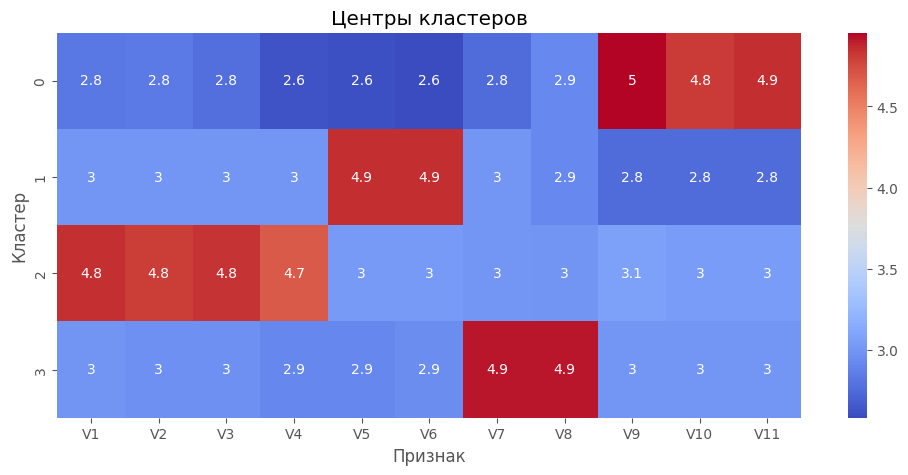

In [69]:
# Тепловая карта центров кластеров
plt.figure(figsize=(12, 5))
sns.heatmap(centers, annot=True,  cmap='coolwarm')
plt.title('Центры кластеров')
plt.xlabel('Признак')
plt.ylabel('Кластер')
plt.show()

Среднее расстояние от объектов до центра своего кластера небольшое: от 0,37 до 1,39. Расстояния между самими центроидами намного больше, от 3,90 до 5,19. Значит, внутри кластеров объекты собраны плотно, а сами кластеры далеко друг от друга.

Ближе всего центры кластеров 1 и 3: сладкоежки и концентрация. Дальше всего кластеры 0 и 2: лечебный и свежее дыхание.

Это объясняется блоками высказываний, по которым различаются кластеры. Сладкоежки и концентрация расходятся только в двух парах высказываний (V5-V6 и V7-V8), а по остальным семи оба кластера отвечают нейтрально, около 3. Лечебный кластер и кластер свежего дыхания расходятся сразу в семи высказываниях (V1-V4 и V9-V11). К тому же лечебный кластер оценивает свежесть даже ниже нейтрального, поэтому расстояние между ними самое большое.

In [ ]:
sizes = df.groupby('cluster').size()
pd.DataFrame({'Человек': sizes,
              'Доля, %': (sizes / len(df) * 100).round(1)})

,Человек,"Доля, %"
cluster,,
0,108,32.0
1,61,18.0
2,110,32.5
3,59,17.5


In [ ]:
means = df.groupby('cluster').mean().round(2)
means

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


Средняя оценка по каждому блоку высказываний

In [ ]:
blocks = {'Освежение (V1–V4)':    ['V1', 'V2', 'V3', 'V4'],
          'Сладкое (V5–V6)':      ['V5', 'V6'],
          'Концентрация (V7–V8)': ['V7', 'V8'],
          'Лечение (V9–V11)':     ['V9', 'V10', 'V11']}

pd.DataFrame({name: means[cols].mean(axis=1) for name, cols in blocks.items()}).round(2)

,Освежение (V1–V4),Сладкое (V5–V6),Концентрация (V7–V8),Лечение (V9–V11)
cluster,,,,
0,2.76,2.60,2.84,4.87
1,3.00,4.85,2.96,2.75
2,4.79,3.04,3.00,3.06
3,2.97,2.94,4.92,3.00


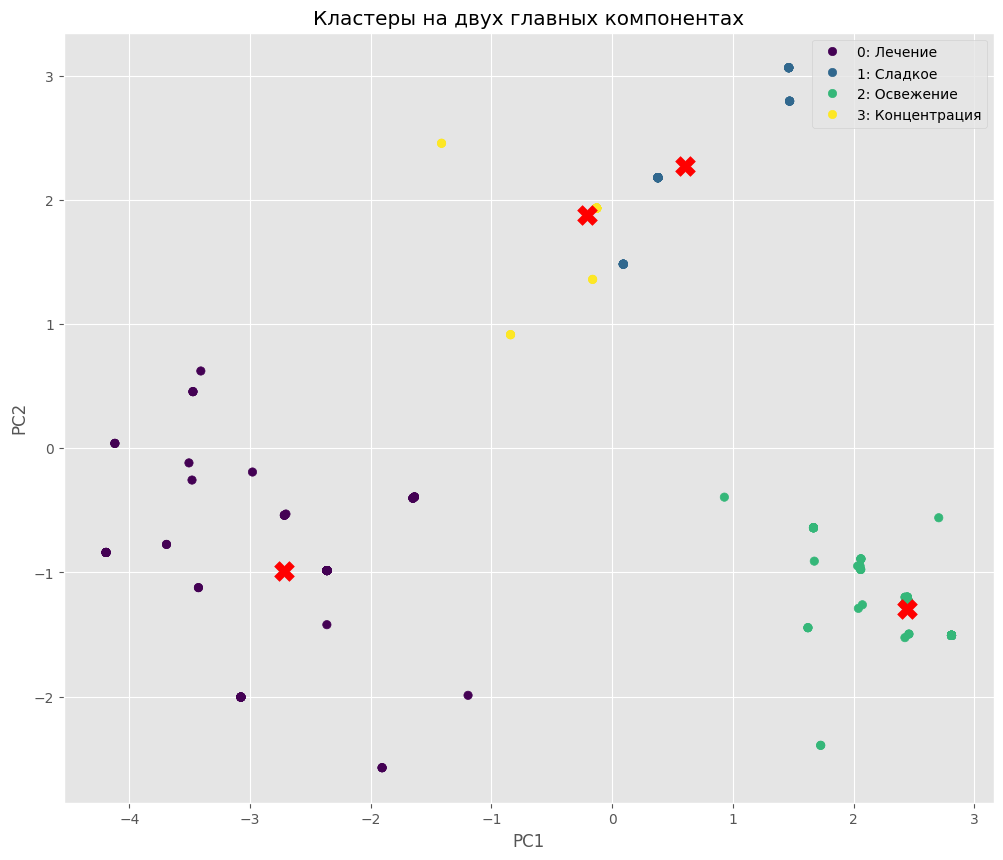

In [ ]:
from sklearn.decomposition import PCA

names = ['0: Лечение', '1: Сладкое', '2: Освежение', '3: Концентрация']

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df.iloc[:, :11])
centers_pca = pca.transform(centers)    
plt.figure(figsize=(12, 10))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200)
plt.legend(sc.legend_elements()[0], names)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Кластеры на двух главных компонентах')
plt.show()

На плоскости двух главных компонент лечебный кластер (0, слева) и кластер свежего дыхания (2, справа внизу) находятся далеко друг от друга и от остальных. Сладкоежки (1) и концентрация (3) расположены сверху рядом, их центры почти соседние: в проекции на две компоненты эти группы видны хуже, потому что отличаются в основном по V5–V8. У кластера 3 видно мало точек: большинство его респондентов ответили одинаково и лежат в одной точке под крестиком центра.

## Выводы:
Первый кластер (108 человек) едят леденцы, когда болеют. Они высоко оценили V9–V11: боль в горле, заложенный нос, плохое самочувствие. Остальные причины у них оценены даже ниже тройки, так что для них леденец скорее лекарство, чем сладость.

Во второй кластер (110 человек) попали те, кому важно свежее дыхание. У них высокие оценки по V1–V4: освежить дыхание и рот, убрать неприятный вкус, чувствовать себя увереннее при общении. Другие высказывания они оценили нейтрально.

Третий кластер (59 человек) едят леденцы, чтобы сосредоточиться или отвлечься на пару минут и подумать (V7 и V8 по 4,92). Скорее всего, это люди, которые много работают или учатся.

Четвёртый кластер (61 человек) – сладкоежки. Для них леденец просто заменяет конфеты, когда хочется чего-нибудь сладкого (V5 и V6 по 4,85). Лечебный эффект их почти не интересует (2,75).

В итоге получилось четыре понятных сегмента. Даже самый маленький из них составляет 17,5 % выборки, так что все группы достаточно крупные. Самые большие сегменты связаны с простудой и свежим дыханием, вместе это около двух третей респондентов, поэтому компании в первую очередь стоит ориентироваться на них.